In [6]:
"""
prep.py - audit, clean, split and patch-cut the acne / scar datasets.

Order of work (do not skip steps, do not re-split later):
  1. index_*()      -> one row per photo (+ one row per box) for each dataset
  2. build_manifest -> combine, drop exact duplicates, cluster near-duplicates
  3. assign_splits  -> split BY PHOTO CLUSTER into train / val / test
  4. cut_patches    -> cut patches per split, save images + patches.csv
  5. verify         -> checks that nothing leaks between splits

Patch labels:
  active : box labelled acne/pimple (ACNE04, Roboflow sets)           weak=0
  scar   : box labelled scar (Roboflow sets)                          weak=0
           grid patch from a ScarNet photo (image-level label only)   weak=1
  normal : random patch that does not overlap any box                 weak=1
           (can still contain an unlabelled scar - note as noise)

Run on your own paths: see the example at the bottom.
"""
import json
import random
import hashlib
import xml.etree.ElementTree as ET
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image

IMG_EXT = {".jpg", ".jpeg", ".png", ".jfif", ".bmp", ".webp"}
SEED = 42


# ----------------------------------------------------------------- helpers
def list_images(root):
    return sorted(p for p in Path(root).rglob("*") if p.suffix.lower() in IMG_EXT)


def md5(path):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def dhash(img, size=8):
    """64-bit difference hash. Near-identical photos give hashes a few bits apart."""
    g = img.convert("L").resize((size + 1, size), Image.LANCZOS)
    a = np.asarray(g, dtype=np.int16)
    bits = (a[:, 1:] > a[:, :-1]).flatten()
    return int("".join("1" if b else "0" for b in bits), 2)


def hamming(a, b):
    return bin(a ^ b).count("1")


def rf_group_key(stem):
    """Roboflow names copies like  name_jpg.rf.<hash>  - all copies share the part before '.rf.'"""
    return stem.split(".rf.")[0]


# ----------------------------------------------------------------- 1. index
def index_acne04(root, official_test_file=None):
    """ACNE04: classification/Classification/JPEGImages + detection/Detection/VOC2007/Annotations.
    official_test_file: e.g. .../NNEW_test_0.txt  (first column = file name)."""
    root = Path(root)
    # find the folders wherever they are and whatever their capitalisation
    img_dir = next((p for p in root.rglob("*") if p.is_dir() and p.name.lower() == "jpegimages"), None)
    ann_dir = next((p for p in root.rglob("*") if p.is_dir() and p.name.lower() == "annotations"), None)
    if img_dir is None or ann_dir is None:
        raise FileNotFoundError(f"JPEGImages / Annotations not found under {root}")
    print("ACNE04 images:", img_dir, "\nACNE04 annotations:", ann_dir)
    test_stems = set()
    if official_test_file:
        for line in Path(official_test_file).read_text().splitlines():
            if line.strip():
                test_stems.add(Path(line.split()[0]).stem)
    photos, boxes = [], []
    for p in list_images(img_dir):
        pid = f"acne04/{p.stem}"
        photos.append(dict(photo_id=pid, dataset="acne04", path=str(p), group_key=pid,
                           stratum="acne04", forced_split="test" if p.stem in test_stems else ""))
        xml = ann_dir / f"{p.stem}.xml"
        if xml.exists():
            for obj in ET.parse(xml).getroot().iter("object"):
                bb = obj.find("bndbox")
                x1, y1, x2, y2 = (float(bb.find(k).text) for k in ("xmin", "ymin", "xmax", "ymax"))
                boxes.append(dict(photo_id=pid, x1=x1, y1=y1, x2=x2, y2=y2, label="active"))
    return pd.DataFrame(photos), pd.DataFrame(boxes)


def index_scarnet(root, exclude_classes=("Keloid",)):
    """ScarNet: root/<scar class>/<image>. Image-level labels only (no boxes)."""
    photos = []
    if not Path(root).is_dir():
        raise FileNotFoundError(f"ScarNet folder not found: {root}")
    for cls_dir in sorted(d for d in Path(root).iterdir() if d.is_dir()):
        if cls_dir.name in exclude_classes:
            continue
        for p in list_images(cls_dir):
            pid = f"scarnet/{cls_dir.name}/{p.stem}"
            photos.append(dict(photo_id=pid, dataset="scarnet", path=str(p), group_key=pid,
                               stratum=f"scarnet/{cls_dir.name}", forced_split="",
                               image_label="scar"))
    return pd.DataFrame(photos), pd.DataFrame(columns=["photo_id", "x1", "y1", "x2", "y2", "label"])


def index_roboflow_yolo(root, name, label_map, exclude_keys=()):
    """Roboflow export in YOLO format: root/{train,valid,test}/{images,labels} + data.yaml.
    label_map: class name -> 'active' | 'scar' | None (None = ignore that class).
    exclude_keys: group keys (names before '.rf.') of AI-generated / unusable images."""
    import yaml
    root = Path(root)
    names = yaml.safe_load((root / "data.yaml").read_text())["names"]
    if isinstance(names, dict):
        names = [names[k] for k in sorted(names)]
    photos, boxes, seen = [], [], set()
    for split in ("train", "valid", "test"):
        img_dir, lab_dir = root / split / "images", root / split / "labels"
        if not img_dir.exists():
            continue
        for p in list_images(img_dir):
            key = rf_group_key(p.stem)
            if key in exclude_keys or key in seen:     # one copy per source image
                continue
            seen.add(key)
            pid = f"{name}/{key}"
            with Image.open(p) as im:
                W, H = im.size
            photos.append(dict(photo_id=pid, dataset=name, path=str(p), group_key=pid,
                               stratum=name, forced_split=""))
            lab = lab_dir / f"{p.stem}.txt"
            if not lab.exists():
                continue
            for line in lab.read_text().splitlines():
                v = line.split()
                if len(v) < 5:
                    continue
                label = label_map.get(names[int(v[0])])
                if label is None:
                    continue
                nums = list(map(float, v[1:]))
                if len(nums) == 4:                      # cx cy w h
                    cx, cy, w, h = nums
                    x1, y1, x2, y2 = (cx - w / 2) * W, (cy - h / 2) * H, (cx + w / 2) * W, (cy + h / 2) * H
                else:                                    # polygon -> bounding box
                    xs, ys = nums[0::2], nums[1::2]
                    x1, x2, y1, y2 = min(xs) * W, max(xs) * W, min(ys) * H, max(ys) * H
                boxes.append(dict(photo_id=pid, x1=x1, y1=y1, x2=x2, y2=y2, label=label))
    return pd.DataFrame(photos), pd.DataFrame(boxes)


def index_folder_labels(root, name, folder_to_label):
    """Generic image-level dataset: root/<folder>/<image>; folder_to_label maps folder -> 'scar'/'active'/None.
    Use for sets you have only audited at folder level (e.g. a Kaggle scar set)."""
    photos = []
    for d in sorted(x for x in Path(root).iterdir() if x.is_dir()):
        lab = folder_to_label.get(d.name)
        if lab is None:
            continue
        for p in list_images(d):
            pid = f"{name}/{d.name}/{p.stem}"
            photos.append(dict(photo_id=pid, dataset=name, path=str(p), group_key=pid,
                               stratum=f"{name}/{d.name}", forced_split="", image_label=lab))
    return pd.DataFrame(photos), pd.DataFrame(columns=["photo_id", "x1", "y1", "x2", "y2", "label"])


# ------------------------------------------------------- 2. manifest + dedupe
def build_manifest(indexed, near_dup_bits=4, min_side=64):
    """indexed: list of (photos_df, boxes_df). Returns (manifest, boxes, report).
    - drops unreadable / tiny images and exact duplicates (same md5)
    - clusters near-duplicates (dhash within near_dup_bits) so they always share a split"""
    photos = pd.concat([p for p, _ in indexed], ignore_index=True)
    boxes = pd.concat([b for _, b in indexed if len(b)], ignore_index=True)
    if "image_label" not in photos:
        photos["image_label"] = ""
    photos["image_label"] = photos["image_label"].fillna("")
    rows, report = [], {"input": len(photos), "unreadable_or_tiny": 0, "exact_duplicates": 0}
    seen_md5 = {}
    for r in photos.to_dict("records"):
        try:
            with Image.open(r["path"]) as im:
                im.load()
                if min(im.size) < min_side:
                    raise ValueError("tiny")
                r["width"], r["height"] = im.size
                r["dhash"] = dhash(im)
        except Exception:
            report["unreadable_or_tiny"] += 1
            continue
        r["md5"] = md5(r["path"])
        if r["md5"] in seen_md5:
            report["exact_duplicates"] += 1
            continue
        seen_md5[r["md5"]] = r["photo_id"]
        rows.append(r)
    m = pd.DataFrame(rows)
    parent = list(range(len(m)))                         # union-find over near-duplicates

    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    hs = m["dhash"].tolist()
    for i in range(len(hs)):
        for j in range(i + 1, len(hs)):
            if hamming(hs[i], hs[j]) <= near_dup_bits:
                parent[find(i)] = find(j)
    roots = [find(i) for i in range(len(m))]
    first = {}
    for pid, rt in zip(m["photo_id"], roots):
        first[rt] = min(first.get(rt, pid), pid)
    m["cluster"] = [first[rt] for rt in roots]       # stable id: smallest photo_id in the cluster
    report["near_duplicate_clusters_with_>1_photo"] = int((m.groupby("cluster").size() > 1).sum())
    report["kept"] = len(m)
    boxes = boxes[boxes["photo_id"].isin(set(m["photo_id"]))].reset_index(drop=True)
    return m.drop(columns=["dhash"]), boxes, report


# -------------------------------------------------------------- 3. splitting
def assign_splits(m, fractions=None, default=(0.70, 0.15, 0.15), seed=SEED):
    """Split by CLUSTER (never by patch). A cluster holding a photo with forced_split='test'
    goes to test. fractions: {stratum: (train, val, test)} ; ACNE04 with an official test list
    should use (0.85, 0.15, 0.0) because its test photos are already forced."""
    fractions = fractions or {}
    forced = m[m["forced_split"] != ""].groupby("cluster")["forced_split"].first().to_dict()
    cl = m.groupby("cluster").agg(stratum=("stratum", "first")).reset_index()
    out = {c: s for c, s in forced.items()}
    for stratum, g in cl.groupby("stratum"):
        rng = random.Random(f"{seed}-{stratum}")       # own generator per stratum
        free = sorted(c for c in g["cluster"] if c not in out)
        rng.shuffle(free)
        ftr, fva, fte = fractions.get(stratum, default)
        n = len(free)
        n_te, n_va = int(round(n * fte)), int(round(n * fva))
        for i, c in enumerate(free):
            out[c] = "test" if i < n_te else "val" if i < n_te + n_va else "train"
    m = m.copy()
    m["split"] = m["cluster"].map(out)
    return m


# ------------------------------------------------------------- 4. patch cutting
def _overlap(a, b):
    """fraction of square a covered by box b"""
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    return ix * iy / max(1e-9, (a[2] - a[0]) * (a[3] - a[1]))


def _square(cx, cy, side, W, H):
    side = min(side, W, H)
    x1 = min(max(cx - side / 2, 0), W - side)
    y1 = min(max(cy - side / 2, 0), H - side)
    return (x1, y1, x1 + side, y1 + side)


def cut_patches(m, boxes, out_dir, out_size=224, pad=1.5, min_side=64, min_box=10,
                normal_per_photo=4, scar_grid_per_photo=16, scar_grid_frac=0.30, seed=SEED):
    """Writes out_dir/<split>/<label>/<patch_id>.jpg and out_dir/patches.csv.
    Saved columns include the patch centre (cx, cy, as fractions of the photo) and side, so the
    graph step can use position."""
    rng = random.Random(seed)
    out_dir = Path(out_dir)
    recs = []
    bx = {k: v for k, v in boxes.groupby("photo_id")} if len(boxes) else {}
    for r in m.to_dict("records"):
        with Image.open(r["path"]) as im:
            im = im.convert("RGB")
            W, H = im.size
            b = bx.get(r["photo_id"])
            bl = [] if b is None else list(b[["x1", "y1", "x2", "y2", "label"]].itertuples(index=False, name=None))
            todo = []  # (square, label, weak)
            for x1, y1, x2, y2, lab in bl:
                if max(x2 - x1, y2 - y1) < min_box:      # too small to be a usable lesion crop
                    continue                              # (still counted as occupied below)
                side = max(max(x2 - x1, y2 - y1) * pad, min_side)
                todo.append((_square((x1 + x2) / 2, (y1 + y2) / 2, side, W, H), lab, 0))
            sides = [t[0][2] - t[0][0] for t in todo] or [0.15 * min(W, H)]
            allbox = [(x1, y1, x2, y2) for x1, y1, x2, y2, _ in bl]
            if r["image_label"] == "scar" and not bl:      # image-level scar photo -> grid patches
                side = scar_grid_frac * min(W, H)
                xs = np.linspace(side / 2, W - side / 2, 5)
                ys = np.linspace(side / 2, H - side / 2, 5)
                cells = [(x, y) for x in xs for y in ys]
                rng.shuffle(cells)
                for x, y in cells[:scar_grid_per_photo]:
                    todo.append((_square(x, y, side, W, H), "scar", 1))
            elif r["image_label"] == "active" and not bl:
                pass
            n_norm, tries = 0, 0                            # normal patches away from every box
            if r["image_label"] == "" or bl:
                while n_norm < normal_per_photo and tries < 50:
                    tries += 1
                    s = max(rng.choice(sides), min_side)
                    sq = _square(rng.uniform(s / 2, W - s / 2), rng.uniform(s / 2, H - s / 2), s, W, H)
                    if all(_overlap(sq, bb) < 0.05 for bb in allbox):
                        todo.append((sq, "normal", 1))
                        n_norm += 1
            for i, (sq, lab, weak) in enumerate(todo):
                pid = f"{r['photo_id'].replace('/', '__')}__{i:03d}"
                d = out_dir / r["split"] / lab
                d.mkdir(parents=True, exist_ok=True)
                im.crop(tuple(int(round(v)) for v in sq)).resize((out_size, out_size), Image.BICUBIC) \
                  .save(d / f"{pid}.jpg", quality=95)
                recs.append(dict(patch_id=pid, photo_id=r["photo_id"], dataset=r["dataset"], split=r["split"],
                                 label=lab, weak=weak, cx=(sq[0] + sq[2]) / 2 / W, cy=(sq[1] + sq[3]) / 2 / H,
                                 side=sq[2] - sq[0], path=str(d / f"{pid}.jpg")))
    pd.DataFrame(recs).to_csv(out_dir / "patches.csv", index=False)
    return pd.DataFrame(recs)


# ------------------------------------------------- 4b. grid table (for the graph stage)
def make_grid_table(m, boxes, side_frac=0.10, scar_cap=16, seed=SEED):
    """One row per grid cell of every photo (no images are saved; crop on the fly later).
    Label rule for photos WITH boxes:  a cell that contains the centre of an active/scar box -> that label;
      a cell that touches no box -> 'normal';  anything else (partly overlapping) -> 'ignore'.
    Photos with only an image-level scar label: up to scar_cap random cells, label 'scar', weak=1.
    cx, cy are the cell centre as a fraction of the photo (used for position and for distance)."""
    rng = random.Random(seed)
    bx = {k: v for k, v in boxes.groupby("photo_id")} if len(boxes) else {}
    rows = []
    for r in m.to_dict("records"):
        W, H = r["width"], r["height"]
        side = max(32, int(side_frac * min(W, H)))
        b = bx.get(r["photo_id"])
        bl = [] if b is None else list(b[["x1", "y1", "x2", "y2", "label"]].itertuples(index=False, name=None))
        cells = [(i, j, x, y) for i, y in enumerate(range(0, H - side + 1, side))
                 for j, x in enumerate(range(0, W - side + 1, side))]
        if r["image_label"] == "scar" and not bl:
            rng.shuffle(cells)
            for i, j, x, y in cells[:scar_cap]:
                rows.append(dict(photo_id=r["photo_id"], dataset=r["dataset"], split=r["split"], row=i, col=j,
                                 x1=x, y1=y, x2=x + side, y2=y + side, cx=(x + side / 2) / W, cy=(y + side / 2) / H,
                                 label="scar", weak=1))
            continue
        for i, j, x, y in cells:
            label = "normal"
            for bx1, by1, bx2, by2, lab in bl:
                inter = max(0, min(x + side, bx2) - max(x, bx1)) * max(0, min(y + side, by2) - max(y, by1))
                if inter > 0:
                    mx, my = (bx1 + bx2) / 2, (by1 + by2) / 2
                    label = lab if (x <= mx < x + side and y <= my < y + side) else ("ignore" if label == "normal" else label)
            rows.append(dict(photo_id=r["photo_id"], dataset=r["dataset"], split=r["split"], row=i, col=j,
                             x1=x, y1=y, x2=x + side, y2=y + side, cx=(x + side / 2) / W, cy=(y + side / 2) / H,
                             label=label, weak=0 if bl else 1))
    return pd.DataFrame(rows)


# ------------------------------------------------------------------ 5. verify
def verify(m, patches, grid=None):
    assert m["split"].notna().all(), "photo without split"
    assert (m.groupby("cluster")["split"].nunique() == 1).all(), "a cluster spans two splits"
    assert (patches.groupby("photo_id")["split"].nunique() == 1).all(), "a photo's patches span two splits"
    print("photos per dataset/split:\n", m.pivot_table(index="dataset", columns="split", values="photo_id", aggfunc="count", fill_value=0))
    print("patches per label/split:\n", patches.pivot_table(index="label", columns="split", values="patch_id", aggfunc="count", fill_value=0))
    if grid is not None:
        assert (grid.groupby("photo_id")["split"].nunique() == 1).all(), "a photo's grid cells span two splits"
        print("grid cells per label/split:\n", grid.pivot_table(index="label", columns="split", values="photo_id", aggfunc="count", fill_value=0))
    print("OK: no photo or near-duplicate cluster appears in more than one split.")


# ------------------------------------------------------------------- example
if __name__ == "__main__":
    # EDIT THESE PATHS. Run once; keep manifest.csv and never re-split.
    ACNE04 = "/kaggle/input/<your-acne04-dataset>"
    SCARNET = "/kaggle/input/datasets/malgamage/scarnet/Collected(ScarNet)"
    OUT = Path("/kaggle/working/prep_out")
    OUT.mkdir(parents=True, exist_ok=True)

    indexed = [
        index_acne04(ACNE04, official_test_file=f"{ACNE04}/classification/Classification/NNEW_test_0.txt"),
        index_scarnet(SCARNET, exclude_classes=("Keloid",)),
        # Roboflow sets: pick the mapping after you look at the class names. dark_spot is left out on purpose.
        # index_roboflow_yolo("/kaggle/input/acne-marks", "acne_marks",
        #     {"acne": "active", "pimple": "active", "acne_scar": "scar"}, exclude_keys=set()),
    ]
    m, boxes, report = build_manifest(indexed)
    print(report)
    m = assign_splits(m, fractions={"acne04": (0.85, 0.15, 0.0)})
    m.to_csv(OUT / "manifest.csv", index=False)
    boxes.to_csv(OUT / "boxes.csv", index=False)
    patches = cut_patches(m, boxes, OUT / "patches")
    verify(m, patches)

Writing /kaggle/working/prep.py


In [13]:
import sys; sys.path.insert(0, "/kaggle/working/<your-repo>")
import prep

ACNE04  = "/kaggle/input/datasets/malgamage/acne04"
SCARNET = "/kaggle/input/datasets/malgamage/scarnet/Collected(ScarNet)"
TEST_LIST = "/kaggle/input/datasets/malgamage/acne04/ACNE04/Classification/Classification/NNEW_test_0.txt" 

idx = [prep.index_acne04(ACNE04, official_test_file=TEST_LIST),   
       prep.index_scarnet(SCARNET, exclude_classes=("Keloid", "Hypertrophic"))]
for name, (p, b) in zip(["acne04", "scarnet"], idx):
    print(name, "photos:", len(p), "boxes:", len(b))

m, boxes, report = prep.build_manifest(idx, near_dup_bits=2)      
print(report)
print(m.groupby("dataset").size())
print("official test photos:", (m.forced_split == "test").sum())  

ACNE04 images: /kaggle/input/datasets/malgamage/acne04/ACNE04/Classification/Classification/JPEGImages 
ACNE04 annotations: /kaggle/input/datasets/malgamage/acne04/ACNE04/Detection/Detection/VOC2007/Annotations
acne04 photos: 1457 boxes: 18983
scarnet photos: 150 boxes: 0


/kaggle/working/prep.py:176: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  boxes = pd.concat([b for _, b in indexed], ignore_index=True)


{'input': 1607, 'unreadable_or_tiny': 0, 'exact_duplicates': 39, 'near_duplicate_clusters_with_>1_photo': 20, 'kept': 1568}
dataset
acne04     1419
scarnet     149
dtype: int64
official test photos: 285


In [14]:
sc = idx[1][0]
print(sc["photo_id"].str.split("/").str[1].value_counts())

photo_id
Boxcar      50
Ice Pick    50
Rolling     50
Name: count, dtype: int64


acne04 original: 1457 kept: 1419 removed: 38
scarnet original: 251 kept: 149 removed: 102
boxes kept: 18588 | boxes per photo (median): 7.0
         w      h
min    4.0    4.0
25%   30.0   29.0
50%   92.0   99.0
75%  140.0  142.0
max  514.0  491.0
photos in official test list: 285


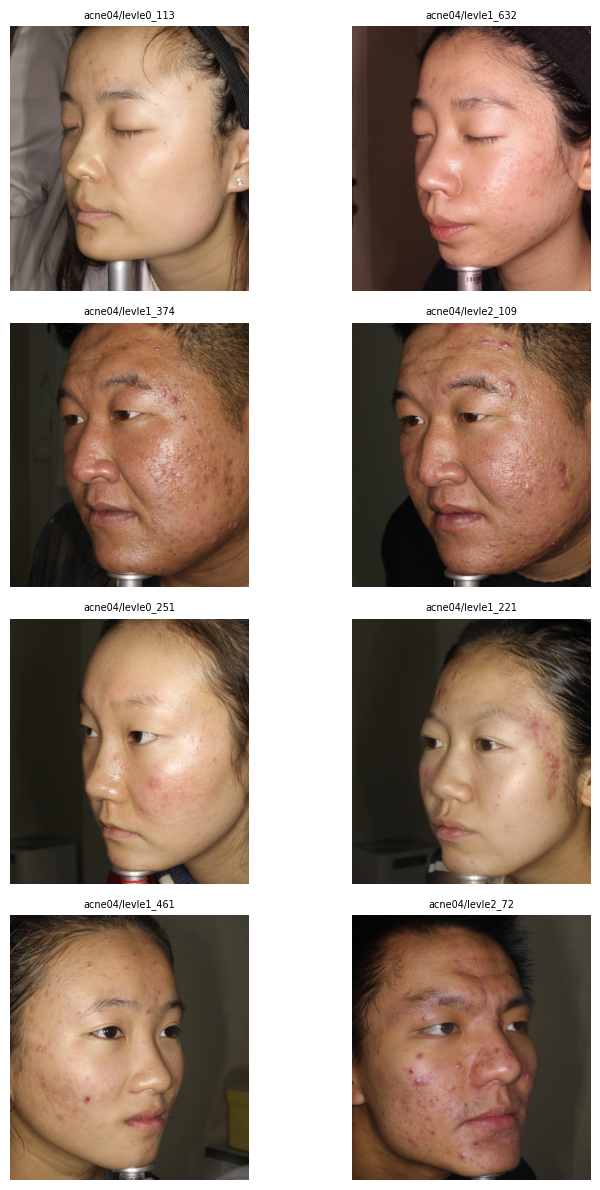

clusters that mix datasets: 0


In [15]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# 1. what was removed, by dataset
orig = {"acne04": 1457, "scarnet": 251}
kept = m.groupby("dataset").size().to_dict()
for d in orig: print(d, "original:", orig[d], "kept:", kept[d], "removed:", orig[d]-kept[d])

# 2. boxes left after removing duplicates, and box sizes
b = boxes.copy()
b["w"] = b.x2 - b.x1; b["h"] = b.y2 - b.y1
print("boxes kept:", len(b), "| boxes per photo (median):", b.groupby("photo_id").size().median())
print(b[["w","h"]].describe().loc[["min","25%","50%","75%","max"]].round(1))
print("photos in official test list:", (m.forced_split=="test").sum())

# 3. look at some near-duplicate clusters (shows up to 4 clusters, 2 photos each)
multi = m.groupby("cluster").filter(lambda g: len(g) > 1)
clusters = list(multi.groupby("cluster"))[:4]
fig, axes = plt.subplots(len(clusters), 2, figsize=(8, 3*len(clusters)))
for row, (c, g) in zip(axes, clusters):
    for ax, (_, r) in zip(row, g.head(2).iterrows()):
        ax.imshow(Image.open(r["path"])); ax.set_title(r["photo_id"][-28:], fontsize=7); ax.axis("off")
plt.tight_layout(); plt.show()
print("clusters that mix datasets:", int((multi.groupby("cluster")["dataset"].nunique() > 1).sum()))

In [10]:
f = "/kaggle/input/datasets/malgamage/acne04/ACNE04/Classification/Classification/NNEW_test_0.txt"
lines = open(f).read().splitlines()
print(len(lines), lines[:3])
stems = {l.split()[0].rsplit(".",1)[0] for l in lines if l.strip()}
have = set(m[m.dataset=="acne04"].photo_id.str.replace("acne04/",""))
print("test names found in photos:", len(stems & have), "of", len(stems))

292 ['levle0_451.jpg  0  2', 'levle0_498.jpg  0  1', 'levle0_485.jpg  0  3']
test names found in photos: 285 of 292


In [11]:
import os
root = "/kaggle/input/datasets/nayanchaure/face-scar"   # the dataset will be somewhere under here
for r, d, f in os.walk(root):
    imgs = [x for x in f if x.lower().endswith((".jpg", ".jpeg", ".png", ".jfif", ".webp"))]
    if imgs and "face-scar" in r.lower():
        print(r, "| images:", len(imgs))

/kaggle/input/datasets/nayanchaure/face-scar/scar | images: 1742
